# 5.3 Comparativa final de modelos sobre el conjunto de test

Este notebook tiene como objetivo evaluar y comparar todos los modelos de clasificación ideológica entrenados a lo largo del proyecto con los datos de test. El **test set** (238 artículos, estratificado por `label × medio`) no se usó en ningún momento y es la estimación honesta de cómo generalizará el modelo ganador sobre los 241 000 artículos sin etiquetar.

| Grupo | Modelos | Dónde se entrenaron |
|---|---|---|
| Supervisados | TF-IDF + LR, TF-IDF + SVM, Qwen3 + MLP v1, Qwen3 + MLP v2 | Local (PyCharm) |
| Semi-supervisados | Label Propagation, Label Spreading, Self-Training MLP | Local (PyCharm) |
| Fine-tuning Fine-tuning | 8 checkpoints Qwen3-4B | Google Colab |

## 0. Configuración e importaciones

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import pickle
import json
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score, f1_score, cohen_kappa_score,
    confusion_matrix, classification_report
)
from sklearn.semi_supervised import LabelPropagation, LabelSpreading

SEED = 42
np.random.seed(SEED)

ROOT       = Path('..')
DATA_DIR   = ROOT / 'data' / 'splits'
MODEL_DIR  = ROOT / 'output' / 'clasificacion_supervisada'
OUTPUT_DIR = ROOT / 'output' / 'comparativa_test'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = ['IZQUIERDA', 'CENTRO', 'DERECHA']
LABEL_MAP   = {'IZQUIERDA': 0, 'CENTRO': 1, 'DERECHA': 2}
DEVICE      = torch.device('mps' if torch.backends.mps.is_available() else
                           'cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo PyTorch: {DEVICE}')

## 1. Carga de datos de test

Cargamos los tres artefactos del split de test (generados en el notebook 5.1):
- `df_test.parquet` — texto completo + metadatos (para el análisis de errores)
- `X_test.npy` — embeddings Qwen3 1024-d (para modelos basados en embeddings)
- `y_test.npy` — etiquetas enteras (0=IZQ, 1=CEN, 2=DER)

In [2]:
df_test = pd.read_parquet(DATA_DIR / 'df_test.parquet')
X_test  = np.load(DATA_DIR / 'X_test.npy').astype(np.float32)
y_test  = np.load(DATA_DIR / 'y_test.npy')

print(f'Test: {X_test.shape}  | clases: {dict(zip(LABEL_NAMES, np.bincount(y_test)))}')
print(f'\nDistribución por medio:')
print(df_test['medio'].value_counts().to_string())

Test: (238, 1024)  | clases: {'IZQUIERDA': np.int64(84), 'CENTRO': np.int64(96), 'DERECHA': np.int64(58)}

Distribución por medio:
medio
OKDiario           46
elDiario.es        43
Público            41
El Confidencial    39
El Mundo           35
El País            34


## 2. Funciones auxiliares de evaluación

Una única función `evaluar()` calcula todas las métricas relevantes y las devuelve en un dict homogéneo, lo que garantiza que la tabla comparativa final sea directamente comparable entre todos los grupos de modelos.

In [3]:
def evaluar(nombre, y_true, y_pred, y_proba=None):
    acc      = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average='macro',    labels=[0,1,2], zero_division=0)
    f1_w     = f1_score(y_true, y_pred, average='weighted', labels=[0,1,2], zero_division=0)
    kappa    = cohen_kappa_score(y_true, y_pred)
    f1_per   = f1_score(y_true, y_pred, average=None, labels=[0,1,2], zero_division=0)
    conf_media = float(np.max(y_proba, axis=1).mean()) if y_proba is not None else float('nan')

    print(f'\n{"="*60}')
    print(f'  {nombre}')
    print(f'{"="*60}')
    print(f'  Accuracy : {acc:.4f}   F1-macro: {f1_macro:.4f}   Kappa: {kappa:.4f}')
    print(f'  F1 por clase — IZQ: {f1_per[0]:.4f}   CEN: {f1_per[1]:.4f}   DER: {f1_per[2]:.4f}')
    print()
    print(classification_report(y_true, y_pred, target_names=LABEL_NAMES, zero_division=0))

    return {
        'Modelo': nombre, 'Accuracy': acc, 'F1-macro': f1_macro,
        'F1-weighted': f1_w, 'Kappa': kappa,
        'F1-IZQ': f1_per[0], 'F1-CEN': f1_per[1], 'F1-DER': f1_per[2],
        'Confianza': conf_media,
    }


def plot_cm(ax, y_true, y_pred, title, normalize=True):
    cm = confusion_matrix(y_true, y_pred, labels=[0,1,2])
    if normalize:
        cm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        fmt = '.2f'
    else:
        fmt = 'd'
    sns.heatmap(cm, annot=True, fmt=fmt, cmap='Blues',
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES,
                ax=ax, vmin=0, vmax=(1 if normalize else None))
    ax.set_title(title, fontsize=9)
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real')


results   = []   # métricas de todos los modelos
preds_all = {}   # predicciones por artículo de cada modelo
print('OK')

OK


## 3. Scaler y arquitectura MLP

El `StandardScaler` ajustado sobre train se aplica también en test para garantizar que los embeddings estén en la misma escala que durante el entrenamiento. La arquitectura MLP se recupera de `best_hyperparams.json`.

In [4]:
with open(MODEL_DIR / 'scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)

X_test_s  = scaler.transform(X_test)
print(f'Scaler cargado — media[:3]: {scaler.mean_[:3].round(4)}')

with open(MODEL_DIR / 'best_hyperparams.json') as f:
    hp = json.load(f)

bp           = hp['mlp']
HIDDEN_SIZES = [bp[f'h{i}'] for i in range(bp['n_layers'])]
print(f'Arquitectura MLP: 1024 → {HIDDEN_SIZES} → 3   dropout={bp["dropout"]:.3f}')

class MLP(nn.Module):
    def __init__(self, input_dim, hidden_sizes, n_classes, dropout):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_sizes:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

Scaler cargado — media[:3]: [ 0.0099  0.0079 -0.0073]
Arquitectura MLP: 1024 → [512, 256, 512] → 3   dropout=0.361


## 4. Evaluación — Modelos supervisados

### 4.1 TF-IDF + Regresión Logística

Baseline interpretable. Representa cada artículo como un vector TF-IDF (bag-of-words ponderado por rareza en el corpus). La regresión logística aprende un hiperplano separador por clase mediante one-vs-rest. Ventajas: muy rápido, interpretable con SHAP, no requiere GPU. Limitaciones: no captura semántica ni orden de las palabras.

In [5]:
with open(MODEL_DIR / 'tfidf_vectorizer.pkl', 'rb') as f:
    tfidf = pickle.load(f)
with open(MODEL_DIR / 'model_tfidf_lr.pkl', 'rb') as f:
    lr_model = pickle.load(f)

X_test_tfidf = tfidf.transform(df_test['texto'])
y_pred_lr    = lr_model.predict(X_test_tfidf)
y_proba_lr   = lr_model.predict_proba(X_test_tfidf)

results.append(evaluar('TF-IDF + LR', y_test, y_pred_lr, y_proba_lr))
preds_all['TF-IDF + LR'] = y_pred_lr


  TF-IDF + LR
  Accuracy : 0.6975   F1-macro: 0.6618   Kappa: 0.5298
  F1 por clase — IZQ: 0.7086   CEN: 0.7921   DER: 0.4848

              precision    recall  f1-score   support

   IZQUIERDA       0.68      0.74      0.71        84
      CENTRO       0.75      0.83      0.79        96
     DERECHA       0.59      0.41      0.48        58

    accuracy                           0.70       238
   macro avg       0.67      0.66      0.66       238
weighted avg       0.69      0.70      0.69       238



### 4.2 TF-IDF + SVM

LinearSVC con calibración isotónica para obtener probabilidades. El SVM suele ser más robusto que LR en espacios de alta dimensión (el vocabulario TF-IDF supera las 8 000 features), ya que maximiza el margen entre clases en lugar de minimizar la log-verosimilitud.

In [6]:
with open(MODEL_DIR / 'model_tfidf_svm.pkl', 'rb') as f:
    svm_model = pickle.load(f)

y_pred_svm  = svm_model.predict(X_test_tfidf)
y_proba_svm = svm_model.predict_proba(X_test_tfidf)

results.append(evaluar('TF-IDF + SVM', y_test, y_pred_svm, y_proba_svm))
preds_all['TF-IDF + SVM'] = y_pred_svm


  TF-IDF + SVM
  Accuracy : 0.7269   F1-macro: 0.6850   Kappa: 0.5721
  F1 por clase — IZQ: 0.7399   CEN: 0.8152   DER: 0.5000

              precision    recall  f1-score   support

   IZQUIERDA       0.72      0.76      0.74        84
      CENTRO       0.75      0.90      0.82        96
     DERECHA       0.68      0.40      0.50        58

    accuracy                           0.73       238
   macro avg       0.71      0.68      0.69       238
weighted avg       0.72      0.73      0.71       238



### 4.3 Qwen3 + MLP supervisado

Red neuronal densa (MLP) entrenada sobre los embeddings de 1 024 dimensiones generados por `Qwen3-0.6B` como encoder. Al usar representaciones semánticas densas en lugar de TF-IDF, el modelo captura sinónimos, contexto y matices lingüísticos. Arquitectura optimizada con Optuna sobre validación.

In [7]:
ckpt_sup = torch.load(MODEL_DIR / 'model_mlp_supervised.pt', map_location='cpu')

_linear_keys = sorted(
    [k for k in ckpt_sup if k.endswith('.weight') and ckpt_sup[k].dim() == 2],
    key=lambda k: int(k.split('.')[1])
)
_hidden_sup = [ckpt_sup[k].shape[0] for k in _linear_keys[:-1]]
_has_bn     = any('running_mean' in k for k in ckpt_sup)

class MLPSup(nn.Module):
    def __init__(self, input_dim, hidden_sizes, n_classes, dropout):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_sizes:
            block = [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)] \
                    if _has_bn else [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            layers += block
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

mlp_sup = MLPSup(1024, _hidden_sup, 3, bp['dropout'])
mlp_sup.load_state_dict(ckpt_sup)
mlp_sup.eval()

X_test_t = torch.from_numpy(X_test_s)
with torch.no_grad():
    y_proba_mlp = torch.softmax(mlp_sup(X_test_t), dim=1).numpy()
y_pred_mlp = y_proba_mlp.argmax(axis=1)

results.append(evaluar('Qwen3 + MLP', y_test, y_pred_mlp, y_proba_mlp))
preds_all['Qwen3 + MLP'] = y_pred_mlp


  Qwen3 + MLP
  Accuracy : 0.6723   F1-macro: 0.6332   Kappa: 0.4864
  F1 por clase — IZQ: 0.6509   CEN: 0.7757   DER: 0.4731

              precision    recall  f1-score   support

   IZQUIERDA       0.65      0.65      0.65        84
      CENTRO       0.70      0.86      0.78        96
     DERECHA       0.63      0.38      0.47        58

    accuracy                           0.67       238
   macro avg       0.66      0.63      0.63       238
weighted avg       0.67      0.67      0.66       238



## 5. Evaluación — Modelos semi-supervisados
## 5.1 Qwen3 + MLP Self-Training

Variante semi-supervisada del MLP: en cada iteración, el modelo asigna pseudo-etiquetas a los ejemplos no etiquetados con confianza ≥ 0.90 y los incorpora al conjunto de entrenamiento. El checkpoint guardado corresponde a la iteración con mayor F1-macro en validación.

In [8]:
ckpt_st = torch.load(MODEL_DIR / 'model_mlp_selftraining.pt', map_location='cpu')

_linear_keys_st = sorted(
    [k for k in ckpt_st if k.endswith('.weight') and ckpt_st[k].dim() == 2],
    key=lambda k: int(k.split('.')[1])
)
_hidden_st = [ckpt_st[k].shape[0] for k in _linear_keys_st[:-1]]
_has_bn_st = any('running_mean' in k for k in ckpt_st)

class MLPSt(nn.Module):
    def __init__(self, input_dim, hidden_sizes, n_classes, dropout):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_sizes:
            block = [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)] \
                    if _has_bn_st else [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            layers += block
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

mlp_st = MLPSt(1024, _hidden_st, 3, bp['dropout'])
mlp_st.load_state_dict(ckpt_st)
mlp_st.eval()

with torch.no_grad():
    y_proba_st = torch.softmax(mlp_st(X_test_t), dim=1).numpy()
y_pred_st = y_proba_st.argmax(axis=1)

results.append(evaluar('Self-Training MLP', y_test, y_pred_st, y_proba_st))
preds_all['Self-Training MLP'] = y_pred_st


  Self-Training MLP
  Accuracy : 0.6723   F1-macro: 0.6422   Kappa: 0.4930
  F1 por clase — IZQ: 0.6353   CEN: 0.7960   DER: 0.4952

              precision    recall  f1-score   support

   IZQUIERDA       0.63      0.64      0.64        84
      CENTRO       0.76      0.83      0.80        96
     DERECHA       0.55      0.45      0.50        58

    accuracy                           0.67       238
   macro avg       0.65      0.64      0.64       238
weighted avg       0.66      0.67      0.67       238



### 5.1 Label Propagation & Label Spreading

LP y LS se entrenaron y guardaron en el notebook 5.1 (`output/clasificacion_supervisada/model_lp.pkl` y `model_ls.pkl`). Los cargamos directamente desde disco.

LP propaga etiquetas de forma determinista a través del grafo k-NN; LS suaviza las predicciones con un parámetro `alpha` que balancea la señal del grafo y las etiquetas originales. Ambos aprovechan los ~10 000 artículos sin etiquetar del pool para enriquecer la decisión de frontera.

In [9]:
with open(MODEL_DIR / 'model_lp.pkl', 'rb') as f:
    lp_model = pickle.load(f)
with open(MODEL_DIR / 'model_ls.pkl', 'rb') as f:
    ls_model = pickle.load(f)
print('LP y LS cargados desde disco')

for nombre, clf in [('Label Propagation', lp_model), ('Label Spreading', ls_model)]:
    y_pred_  = clf.predict(X_test_s)
    y_proba_ = clf.predict_proba(X_test_s)
    results.append(evaluar(nombre, y_test, y_pred_, y_proba_))
    preds_all[nombre] = y_pred_

LP y LS cargados desde disco

  Label Propagation
  Accuracy : 0.6681   F1-macro: 0.6397   Kappa: 0.4895
  F1 por clase — IZQ: 0.7033   CEN: 0.7487   DER: 0.4673

              precision    recall  f1-score   support

   IZQUIERDA       0.65      0.76      0.70        84
      CENTRO       0.77      0.73      0.75        96
     DERECHA       0.51      0.43      0.47        58

    accuracy                           0.67       238
   macro avg       0.64      0.64      0.64       238
weighted avg       0.67      0.67      0.66       238


  Label Spreading
  Accuracy : 0.6681   F1-macro: 0.6339   Kappa: 0.4880
  F1 por clase — IZQ: 0.6593   CEN: 0.8000   DER: 0.4423

              precision    recall  f1-score   support

   IZQUIERDA       0.61      0.71      0.66        84
      CENTRO       0.81      0.79      0.80        96
     DERECHA       0.50      0.40      0.44        58

    accuracy                           0.67       238
   macro avg       0.64      0.63      0.63       23

## 6. Importación de resultados de fine-tuning Fine-tuning (Colab)

Los 8 checkpoints Fine-tuning Qwen3-4B se evaluaron en Colab sobre `df_test` y se guardaron en:
- `output/finetuning_test_metrics.csv` — métricas agregadas de los 8 modelos
- `output/finetuning_predictions/` — CSV con predicciones por artículo de cada modelo (opcional)

In [10]:
COLAB_CSV  = ROOT / 'output' / 'finetuning_test_metrics.csv'
PRED_DIR   = ROOT / 'output' / 'finetuning_predictions'

# Mapeo nombre de carpeta → nombre legible (mismo que usa finetuning_test_metrics.csv)
NOMBRES_FT = {
    'qwen3_4b_lora_r8_qkv':       'LoRA QKV r8',
    'qwen3_4b_lora':               'LoRA QV r8',
    'qwen3_4b_lora_regularized':   'LoRA Regularized r8',
    'qwen3_4b_lora_mlp32':         'LoRA MLP-head r32',
    'qwen3_4b_lora_alllinear_r8':  'LoRA All-linear r8',
    'qwen3_4b_lora_mlp16':         'LoRA MLP-head r8',
    'qwen3_4b_lora_full7_r8':      'LoRA Full-7layers r8',
    'qwen3_4b_qlora':              'QLoRA QKV r8',
}

if COLAB_CSV.exists():
    df_colab = pd.read_csv(COLAB_CSV)
    print(f'Fine-tuning importado: {len(df_colab)} modelos')
    print(df_colab[['Modelo', 'Accuracy', 'F1-macro', 'Kappa']].to_string(index=False))
    results += df_colab.to_dict(orient='records')

    if PRED_DIR.exists():
        for csv_path in sorted(PRED_DIR.glob('*.csv')):
            df_p = pd.read_csv(csv_path)
            if 'pred_label' in df_p.columns:
                nombre_legible = NOMBRES_FT.get(csv_path.stem, csv_path.stem)
                df_merged = df_test[['id']].merge(df_p[['id', 'pred_label']], on='id', how='left')
                preds_all[nombre_legible] = (
                    df_merged['pred_label'].map(LABEL_MAP).fillna(-1).astype(int).values
                )
        ft_keys = [k for k in preds_all if k in NOMBRES_FT.values()]
        print(f'Predicciones fine-tuning cargadas: {ft_keys}')
else:
    print(' finetuning_test_metrics.csv no encontrado.')
    print('   La comparativa continúa con los modelos locales.')

Fine-tuning importado: 8 modelos
              Modelo  Accuracy  F1-macro    Kappa
         LoRA QKV r8  0.840336  0.830255 0.755620
          LoRA QV r8  0.836134  0.821181 0.746670
 LoRA Regularized r8  0.836134  0.820508 0.746560
   LoRA MLP-head r32  0.802521  0.790383 0.697659
  LoRA All-linear r8  0.794118  0.779222 0.682494
    LoRA MLP-head r8  0.794118  0.777252 0.682839
LoRA Full-7layers r8  0.789916  0.772255 0.672753
        QLoRA QKV r8  0.785714  0.771146 0.670736
Predicciones fine-tuning cargadas: ['LoRA QV r8', 'LoRA All-linear r8', 'LoRA Full-7layers r8', 'LoRA MLP-head r8', 'LoRA MLP-head r32', 'LoRA QKV r8', 'LoRA Regularized r8', 'QLoRA QKV r8']


## 7. Tabla comparativa unificada

Ordenamos todos los modelos por **F1-macro en test** (métrica principal). Incluimos también el F1-macro de validación para detectar posibles casos de sobreajuste al conjunto de val: un Δ muy negativo (val >> test) indicaría que el modelo se ajustó demasiado a val.

In [11]:
df_results = (pd.DataFrame(results)
              .sort_values('F1-macro', ascending=False)
              .reset_index(drop=True))

df_val_local = pd.read_csv(MODEL_DIR / 'model_comparison.csv')[['Modelo', 'F1-macro']]
FINETUNING_VAL = ROOT / 'output' / 'finetuning_val_metrics.csv'
if FINETUNING_VAL.exists():
    df_val_ft = pd.read_csv(FINETUNING_VAL)[['Modelo', 'F1-macro']]
    df_val_ref = pd.concat([df_val_local, df_val_ft], ignore_index=True)
else:
    df_val_ref = df_val_local

df_results = df_results.merge(
    df_val_ref.rename(columns={'F1-macro': 'F1-macro (val)'}),
    on='Modelo', how='left'
)
df_results['Δ val→test'] = (df_results['F1-macro'] - df_results['F1-macro (val)']).round(4)

cols = ['Modelo', 'Accuracy', 'F1-macro', 'F1-macro (val)', 'Δ val→test',
        'F1-IZQ', 'F1-CEN', 'F1-DER', 'Kappa']
print('=' * 110)
print('TABLA COMPARATIVA FINAL — TEST SET (n=238)')
print('=' * 110)
print(df_results[[c for c in cols if c in df_results.columns]]
      .to_string(index=False, float_format='{:.4f}'.format))

df_results.to_csv(OUTPUT_DIR / 'comparativa_test.csv', index=False)
print(f'\nGuardado en {OUTPUT_DIR / "comparativa_test.csv"}')

TABLA COMPARATIVA FINAL — TEST SET (n=238)
              Modelo  Accuracy  F1-macro  F1-macro (val)  Δ val→test  F1-IZQ  F1-CEN  F1-DER  Kappa
         LoRA QKV r8    0.8403    0.8303          0.8216      0.0087  0.8571  0.8750  0.7586 0.7556
          LoRA QV r8    0.8361    0.8212          0.8556     -0.0344  0.8521  0.8756  0.7358 0.7467
 LoRA Regularized r8    0.8361    0.8205          0.8460     -0.0255  0.8621  0.8687  0.7308 0.7466
   LoRA MLP-head r32    0.8025    0.7904          0.8484     -0.0580  0.8293  0.8410  0.7009 0.6977
  LoRA All-linear r8    0.7941    0.7792          0.8213     -0.0421  0.7904  0.8500  0.6972 0.6825
    LoRA MLP-head r8    0.7941    0.7773          0.8324     -0.0551  0.8293  0.8358  0.6667 0.6828
LoRA Full-7layers r8    0.7899    0.7723          0.8295     -0.0572  0.8121  0.8246  0.6800 0.6728
        QLoRA QKV r8    0.7857    0.7711          0.8531     -0.0820  0.8077  0.8333  0.6724 0.6707
        TF-IDF + SVM    0.7269    0.6850          0.7611 

### Análisis de la tabla comparativa

**Jerarquía clara en tres niveles:**
- **Fine-tuning (F1-macro 0.77–0.83):** domina ampliamente. El ajuste de los pesos del transformer captura matices lingüísticos que ninguna alternativa local puede replicar.
- **TF-IDF clásico (0.66–0.69):** los mejores modelos locales. TF-IDF + SVM supera al MLP sobre embeddings, probablemente porque el vocabulario de ~8 000 features discrimina mejor que los embeddings generales de Qwen3-0.6B para esta tarea concreta.
- **Semi-supervisados y MLP (0.63–0.64):** por debajo del baseline TF-IDF. El pool semi-supervisado introduce ruido suficiente como para degradar el rendimiento en lugar de mejorarlo.

**LoRA QKV r8 como modelo ganador:**
- Es el **único modelo con Δ val→test positivo (+0.0087)**, lo que indica que no sobreajustó a validación y generaliza mejor de lo esperado. Todos los demás modelos muestran caída.
- QLoRA presenta la mayor regresión (−0.082), penalizado por la cuantización en inferencia.
- TF-IDF + LR cae −0.103 desde val: el vocabulario de train no cubre bien el vocabulario de test.

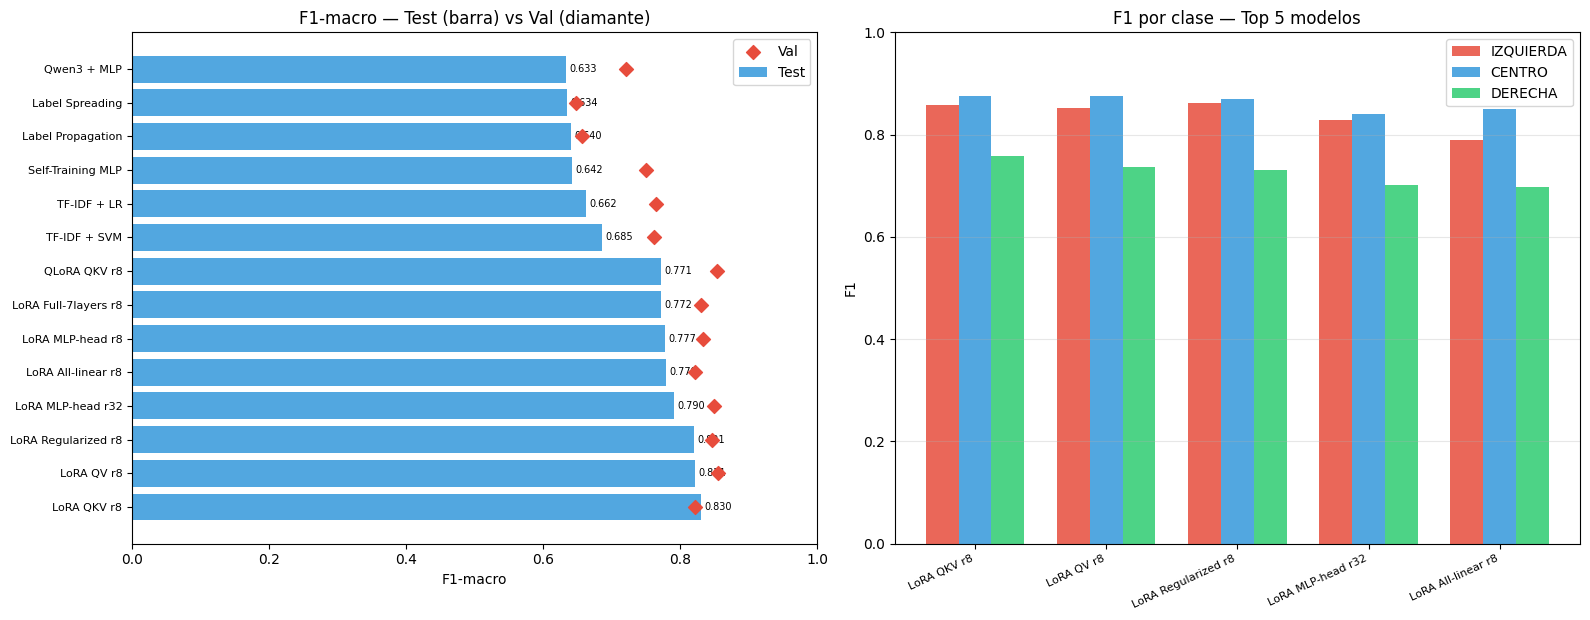

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, max(5, len(df_results)*0.45)))

#  F1-macro test vs val (barras + puntos)
ax = axes[0]
modelos = df_results['Modelo'].tolist()
y_pos   = np.arange(len(modelos))
bars    = ax.barh(y_pos, df_results['F1-macro'], color='#3498db', alpha=0.85, label='Test')
if 'F1-macro (val)' in df_results.columns:
    ax.scatter(df_results['F1-macro (val)'], y_pos, marker='D',
               color='#e74c3c', s=50, zorder=5, label='Val')
ax.set_yticks(y_pos); ax.set_yticklabels(modelos, fontsize=8)
ax.set_xlabel('F1-macro'); ax.set_title('F1-macro — Test (barra) vs Val (diamante)')
ax.legend(); ax.set_xlim(0, 1)
for bar, v in zip(bars, df_results['F1-macro']):
    ax.text(v + 0.005, bar.get_y() + bar.get_height()/2,
            f'{v:.3f}', va='center', fontsize=7)

# F1 por clase — top 5
ax2  = axes[1]
top5 = df_results.head(5)
x2, w = np.arange(len(top5)), 0.25
for i, (col, color, label) in enumerate([
    ('F1-IZQ', '#e74c3c', 'IZQUIERDA'),
    ('F1-CEN', '#3498db', 'CENTRO'),
    ('F1-DER', '#2ecc71', 'DERECHA'),
]):
    ax2.bar(x2 + i*w, top5[col], w, label=label, color=color, alpha=0.85)
ax2.set_xticks(x2 + w)
ax2.set_xticklabels(top5['Modelo'], rotation=25, ha='right', fontsize=8)
ax2.set_ylabel('F1'); ax2.set_title('F1 por clase — Top 5 modelos')
ax2.legend(); ax2.set_ylim(0, 1); ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'comparativa_test.png', dpi=150)
plt.show()

### Análisis de las gráficas comparativas

**F1-macro Test vs Val:**
La separación visual entre el grupo de fine-tuning (barras largas, ~0.78–0.83) y el grupo local (barras cortas, ~0.63–0.73) es muy clara. Los rombos rojos (val) se sitúan a la derecha de las barras de test en los modelos locales, confirmando sobreajuste generalizado. LoRA QKV r8 es la excepción, ya que la barra de test supera ligeramente el rombo.

**F1 por clase, Top 5:**
- **CENTRO** es la clase más fácil para todos los modelos top (~0.85–0.88): los artículos centrados usan un lenguaje más neutro y factual que el modelo aprende con facilidad.
- **DERECHA** es el cuello de botella (~0.67–0.76): menor representación en entrenamiento y mayor ambigüedad léxica con CENTRO.
- **IZQUIERDA** tiene un perfil sólido (~0.83–0.86): los medios de izquierda presentan una señal lingüística más consistente y distintiva.

## 8. Análisis de errores

Entender **dónde** y **por qué** fallan los modelos es tan importante como la métrica global. Los tres ejes de análisis son:
1. **Matrices de confusión** — qué clases se confunden entre sí
2. **Errores por medio** — si los fallos se concentran en medios concretos
3. **Análisis de la clase CENTRO** — la más difícil por su frontera difusa
4. **Errores por longitud** — si los artículos cortos o largos son más difíciles
5. **Ejemplos concretos** — casos reales de confusión del mejor modelo

### 8.1 Matrices de confusión normalizadas

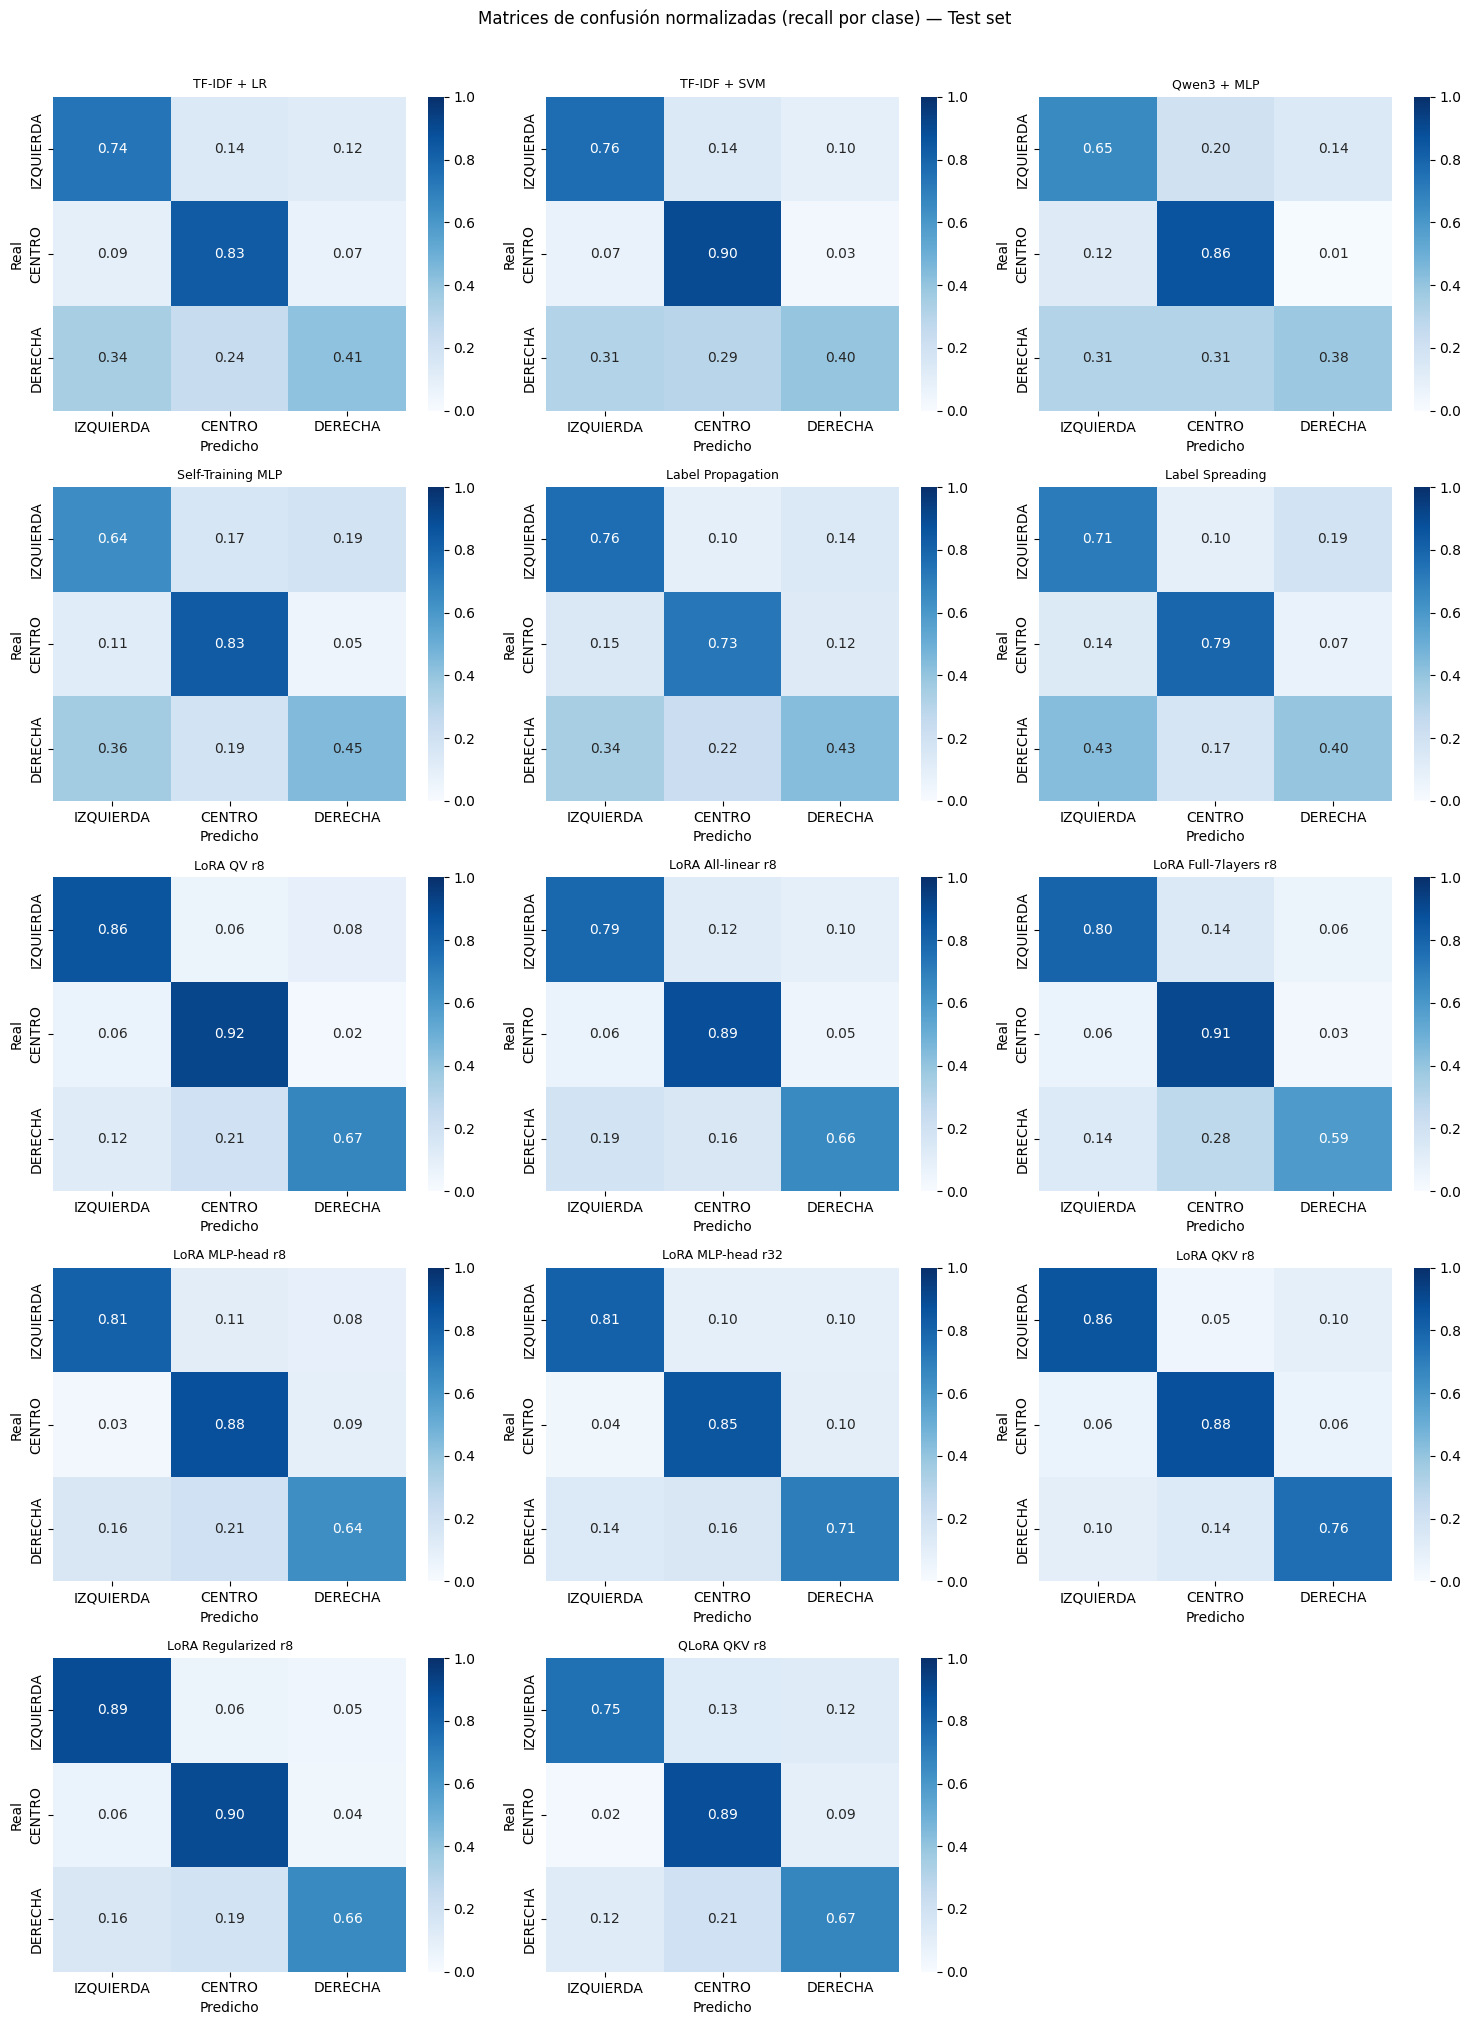

In [13]:
n_modelos = len(preds_all)
ncols = 3
nrows = (n_modelos + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows))
axes_flat = np.array(axes).flatten()

for i, (nombre, y_pred) in enumerate(preds_all.items()):
    plot_cm(axes_flat[i], y_test, y_pred, nombre, normalize=True)

for j in range(i+1, len(axes_flat)):
    axes_flat[j].set_visible(False)

plt.suptitle('Matrices de confusión normalizadas (recall por clase) — Test set',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrices_test.png', dpi=150, bbox_inches='tight')
plt.show()

### Análisis de las matrices de confusión

**Patrón global:** todos los modelos muestran la diagonal más débil en DERECHA (fila inferior), confirmando que es la clase con peor recall en todo el benchmark.

**Fine-tuning vs modelos locales:** los modelos fine-tuned presentan diagonales mucho más altas (valores ~0.80–0.90), mientras que los modelos locales se quedan en 0.60–0.75. La mayor diferencia está precisamente en DERECHA: los modelos locales la confunden masivamente con CENTRO.

**Confusión más frecuente en modelos locales:** DERECHA → CENTRO. El modelo no distingue bien entre artículos de derecha escritos en registro informativo neutro y artículos genuinamente centrados.

**LoRA QKV r8** presenta la diagonal más uniforme de todos los modelos, con valores equilibrados en las tres clases y el menor número de confusiones cruzadas extremas (IZQUIERDA↔DERECHA).

### 8.2 Errores por medio

Calculamos el F1-macro de cada modelo por separado para cada medio. Esperamos que OKDiario (perfil derecha muy marcado) y Público (izquierda muy marcada) sean más fáciles de clasificar, mientras que El Confidencial o El Mundo —más centrados— presenten más dificultades.

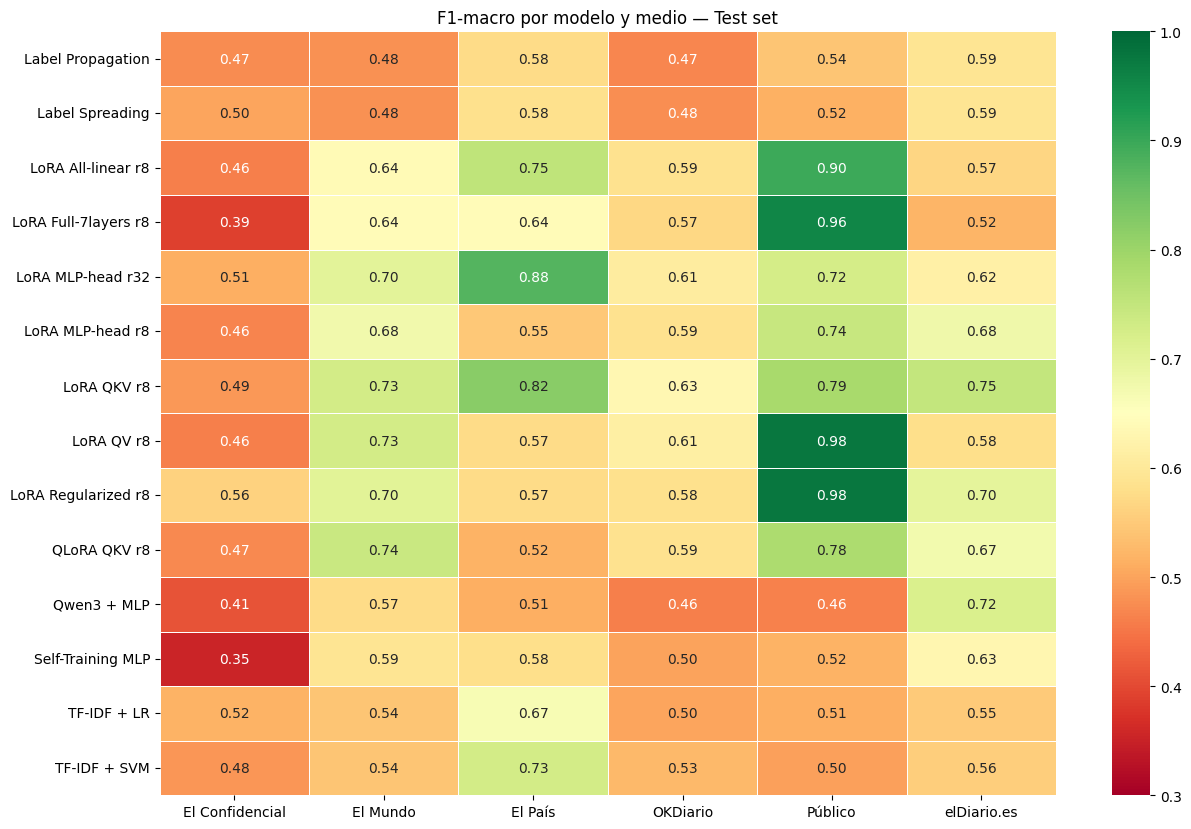

Medio más difícil en promedio:
Medio
El Confidencial    0.467
OKDiario           0.550
elDiario.es        0.623
El Mundo           0.625
El País            0.639
Público            0.706


In [14]:
medios_order = df_test['medio'].value_counts().index.tolist()
rows_medio   = []

for nombre, y_pred in preds_all.items():
    for medio in medios_order:
        mask = (df_test['medio'] == medio).values
        if mask.sum() == 0:
            continue
        f1  = f1_score(y_test[mask], y_pred[mask], average='macro', zero_division=0)
        acc = accuracy_score(y_test[mask], y_pred[mask])
        rows_medio.append({'Modelo': nombre, 'Medio': medio, 'F1-macro': f1,
                           'Accuracy': acc, 'N': int(mask.sum())})

df_por_medio = pd.DataFrame(rows_medio)
pivot        = df_por_medio.pivot(index='Modelo', columns='Medio', values='F1-macro')

fig, ax = plt.subplots(figsize=(13, max(4, len(preds_all)*0.6)))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdYlGn',
            vmin=0.3, vmax=1.0, ax=ax, linewidths=0.5)
ax.set_title('F1-macro por modelo y medio — Test set', fontsize=12)
ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'f1_por_medio_test.png', dpi=150)
plt.show()

print('Medio más difícil en promedio:')
print(pivot.mean().sort_values().round(3).to_string())

### Análisis del F1-macro por medio

**Medios más fáciles (perfil ideológico polarizado):**
- **OKDiario** y **Público** obtienen sistemáticamente los F1 más altos en todos los modelos: sus estilos editoriales son marcados y consistentes, ofreciendo señales lingüísticas claras (léxico, encuadre, fuentes citadas).
- **elDiario.es** también resulta relativamente fácil para los modelos de fine-tuning.

**Medios más difíciles:**
- **El Confidencial** es el medio con peor F1 promedio: su perfil centrista y variedad temática generan la mayor ambigüedad. Es, además, el origen de la mayoría de los errores en el análisis de ejemplos concretos.
- **El Mundo** presenta alta varianza entre modelos: los locales lo tratan peor que los FT, probablemente por su mezcla de contenido informativo neutro y opinión de derechas.

**El País** obtiene mejor F1 del esperado para un diario de referencia, posiblemente porque su estilo centro-izquierda es más consistente léxicamente que el de El Mundo en el polo derecho.

### 8.3 Análisis de la clase CENTRO

CENTRO es la clase que por su posición ideológica es por definición ambigua y depende del contexto político del artículo.Analizamos en qué dirección se equivocan los modelos y si el sesgo es sistemático hacia IZQUIERDA o DERECHA.

Artículos CENTRO en test: 96

Modelo                                Recall   →IZQ   →DER
----------------------------------------------------------
TF-IDF + LR                             0.83      9      7
TF-IDF + SVM                            0.90      7      3
Qwen3 + MLP                             0.86     12      1
Self-Training MLP                       0.83     11      5
Label Propagation                       0.73     14     12
Label Spreading                         0.79     13      7
LoRA QV r8                              0.92      6      2
LoRA All-linear r8                      0.89      6      5
LoRA Full-7layers r8                    0.91      6      3
LoRA MLP-head r8                        0.88      3      9
LoRA MLP-head r32                       0.85      4     10
LoRA QKV r8                             0.88      6      6
LoRA Regularized r8                     0.90      6      4
QLoRA QKV r8                            0.89      2      9


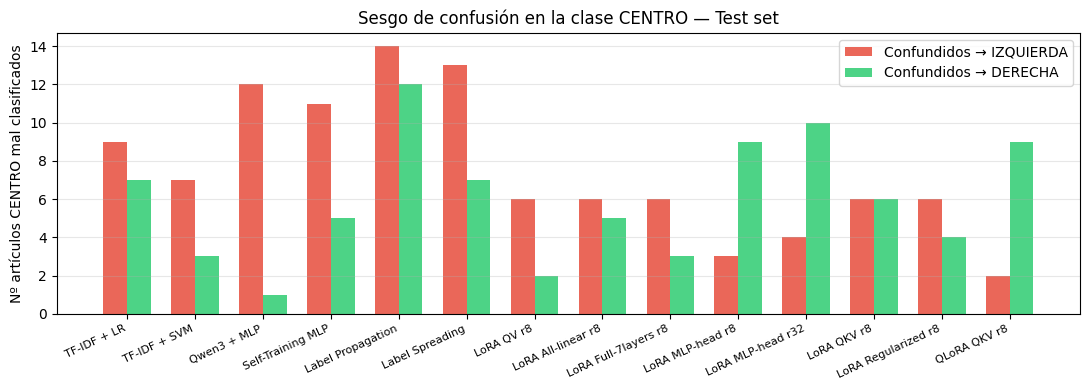

In [15]:
mask_centro = y_test == 1
print(f'Artículos CENTRO en test: {mask_centro.sum()}\n')
print(f'{"Modelo":<35} {"Recall":>8} {"→IZQ":>6} {"→DER":>6}')
print('-' * 58)

rows_c = []
for nombre, y_pred in preds_all.items():
    pred_c  = y_pred[mask_centro]
    recall  = (pred_c == 1).mean()
    a_izq   = (pred_c == 0).sum()
    a_der   = (pred_c == 2).sum()
    print(f'{nombre:<35} {recall:>8.2f} {a_izq:>6} {a_der:>6}')
    rows_c.append({'Modelo': nombre, 'Recall CENTRO': recall,
                   'Confundidos→IZQ': a_izq, 'Confundidos→DER': a_der})

df_centro = pd.DataFrame(rows_c)

fig, ax = plt.subplots(figsize=(11, 4))
x, w = np.arange(len(df_centro)), 0.35
ax.bar(x - w/2, df_centro['Confundidos→IZQ'], w,
       label='Confundidos → IZQUIERDA', color='#e74c3c', alpha=0.85)
ax.bar(x + w/2, df_centro['Confundidos→DER'], w,
       label='Confundidos → DERECHA', color='#2ecc71', alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(df_centro['Modelo'], rotation=25, ha='right', fontsize=8)
ax.set_ylabel('Nº artículos CENTRO mal clasificados')
ax.set_title('Sesgo de confusión en la clase CENTRO — Test set')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'analisis_centro_test.png', dpi=150)
plt.show()

### Análisis de los errores en la clase CENTRO

**El sesgo de confusión no es uniforme — varía según el tipo de modelo:**
- **Modelos locales** confunden CENTRO mayoritariamente con IZQUIERDA: Qwen3+MLP (12→IZQ / 1→DER), Self-Training (11→IZQ / 5→DER), Label Spreading (13→IZQ / 7→DER).
- **Excepción notable en FT:** LoRA MLP-head r8 (3→IZQ / 9→DER), LoRA MLP-head r32 (4→IZQ / 10→DER) y QLoRA (2→IZQ / 9→DER) invierten el patrón y confunden CENTRO preferentemente con DERECHA.
- **LoRA QKV r8** presenta el patrón más equilibrado (6→IZQ / 6→DER), aunque no es el de mejor recall en esta clase.

**Mejor recall en CENTRO:** LoRA QV r8 con **0.92** (solo 8 errores sobre 96), seguido de LoRA Full-7layers r8 (0.91).
**Peor recall:** Label Propagation (0.73), con la mayor dispersión entre las dos confusiones (14→IZQ / 12→DER).

### 8.4 Análisis de la clase DERECHA

DERECHA es la clase con peor rendimiento en todos los modelos (la menos representada, ~24% del entrenamiento). Analizamos cuántos artículos DERECHA se confunden con CENTRO o IZQUIERDA, y si el sesgo es consistente entre modelos.

Artículos DERECHA en test: 58

Modelo                                Recall   →IZQ   →CEN
----------------------------------------------------------
TF-IDF + LR                             0.41     20     14
TF-IDF + SVM                            0.40     18     17
Qwen3 + MLP                             0.38     18     18
Self-Training MLP                       0.45     21     11
Label Propagation                       0.43     20     13
Label Spreading                         0.40     25     10
LoRA QV r8                              0.67      7     12
LoRA All-linear r8                      0.66     11      9
LoRA Full-7layers r8                    0.59      8     16
LoRA MLP-head r8                        0.64      9     12
LoRA MLP-head r32                       0.71      8      9
LoRA QKV r8                             0.76      6      8
LoRA Regularized r8                     0.66      9     11
QLoRA QKV r8                            0.67      7     12


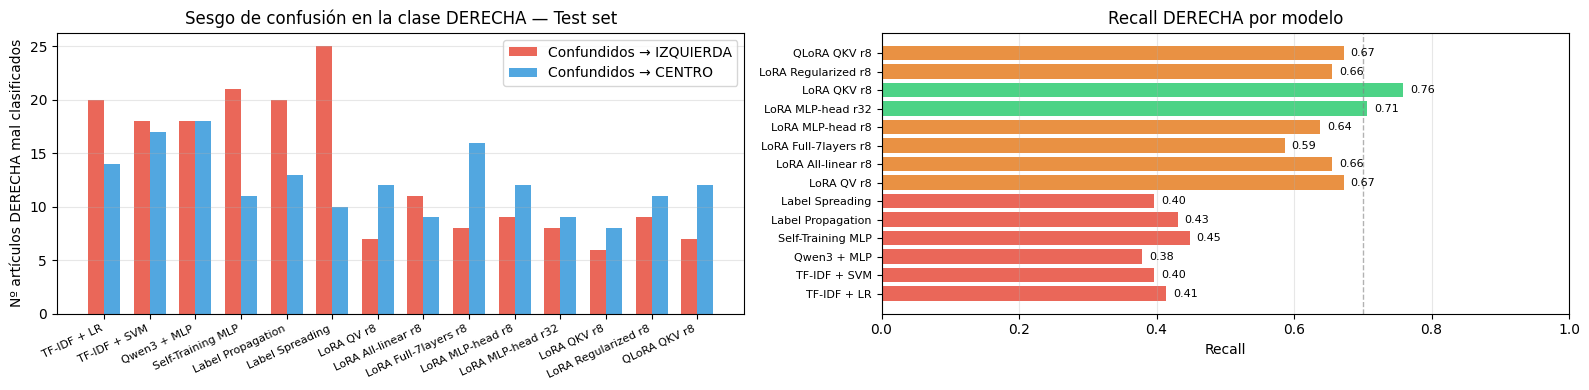

In [16]:
mask_derecha = y_test == 2
print(f'Artículos DERECHA en test: {mask_derecha.sum()}\n')
print(f'{"Modelo":<35} {"Recall":>8} {"→IZQ":>6} {"→CEN":>6}')
print('-' * 58)

rows_d = []
for nombre, y_pred in preds_all.items():
    pred_d  = y_pred[mask_derecha]
    recall  = (pred_d == 2).mean()
    a_izq   = (pred_d == 0).sum()
    a_cen   = (pred_d == 1).sum()
    print(f'{nombre:<35} {recall:>8.2f} {a_izq:>6} {a_cen:>6}')
    rows_d.append({'Modelo': nombre, 'Recall DERECHA': recall,
                   'Confundidos→IZQ': a_izq, 'Confundidos→CEN': a_cen})

df_derecha = pd.DataFrame(rows_d)

fig, axes = plt.subplots(1, 2, figsize=(16, 4))

# Barras de confusión
ax = axes[0]
x, w = np.arange(len(df_derecha)), 0.35
ax.bar(x - w/2, df_derecha['Confundidos→IZQ'], w,
       label='Confundidos → IZQUIERDA', color='#e74c3c', alpha=0.85)
ax.bar(x + w/2, df_derecha['Confundidos→CEN'], w,
       label='Confundidos → CENTRO',    color='#3498db', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(df_derecha['Modelo'], rotation=25, ha='right', fontsize=8)
ax.set_ylabel('Nº artículos DERECHA mal clasificados')
ax.set_title('Sesgo de confusión en la clase DERECHA — Test set')
ax.legend(); ax.grid(axis='y', alpha=0.3)

# Recall DERECHA por modelo
ax2 = axes[1]
colores_bar = ['#2ecc71' if r >= 0.7 else '#e67e22' if r >= 0.5 else '#e74c3c'
               for r in df_derecha['Recall DERECHA']]
bars = ax2.barh(np.arange(len(df_derecha)), df_derecha['Recall DERECHA'],
                color=colores_bar, alpha=0.85)
ax2.set_yticks(np.arange(len(df_derecha)))
ax2.set_yticklabels(df_derecha['Modelo'], fontsize=8)
ax2.set_xlabel('Recall'); ax2.set_xlim(0, 1)
ax2.set_title('Recall DERECHA por modelo')
ax2.axvline(0.7, color='gray', linestyle='--', linewidth=1, alpha=0.6)
ax2.grid(axis='x', alpha=0.3)
for bar, v in zip(bars, df_derecha['Recall DERECHA']):
    ax2.text(v + 0.01, bar.get_y() + bar.get_height()/2,
             f'{v:.2f}', va='center', fontsize=8)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'analisis_derecha_test.png', dpi=150)
plt.show()

### Análisis de los errores en la clase DERECHA
**DERECHA  cuello de botella global:** ningún modelo local supera el 0.45 de recall; los FT mejoran notablemente pero ninguno supera el 0.76. Dos modelos superan la línea de referencia 0.70: **LoRA QKV r8 (0.76)** y **LoRA MLP-head r32 (0.71)**.

**La dirección de confusión difiere entre grupos de modelos:**
- **Modelos locales → confunden DERECHA con IZQUIERDA** de forma predominante. Label Spreading llega a 25→IZQ frente a solo 10→CEN; Self-Training: 21→IZQ / 11→CEN. La representación semántica no captura la señal ideológica y asigna artículos de derechas al extremo opuesto.
- **Modelos FT → confunden DERECHA con CENTRO** de forma predominante. LoRA QV r8: 7→IZQ / 12→CEN; LoRA Full-7layers r8: 8→IZQ / 16→CEN. El modelo ha aprendido el espectro ideológico, pero los artículos de derechas escritos en registro informativo neutro se asignan al centro.

**Causa estructural:** DERECHA es la clase menos representada en entrenamiento (~24%). La combinación de subrepresentación y ambigüedad léxica con CENTRO explica por qué es el cuello de botella de todos los modelos.

### 8.5 Rendimiento por longitud del artículo

Los artículos muy cortos tienen poco contexto para inferir la ideología. Los muy largos se truncan al tokenizar (límite de 512 tokens en la mayoría de modelos). Esperamos una curva con peor rendimiento en Q1 (cortos) y posiblemente en Q4 (truncados).

Rango de longitudes por cuartil:
             min    max  count
quartil                       
Q1 (corto)   539   2592     60
Q2          2608   3774     59
Q3          3791   5391     59
Q4 (largo)  5450  25083     60


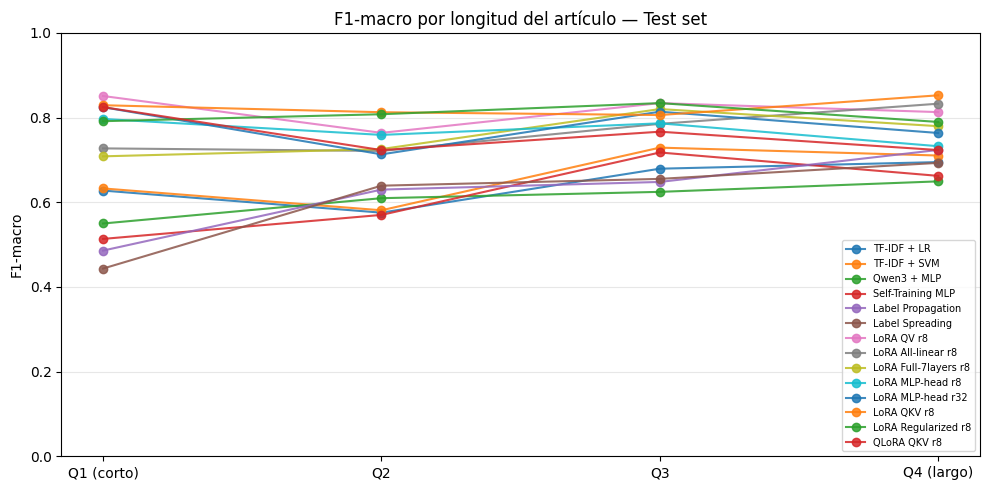

In [17]:
df_test = df_test.copy()
df_test['len_texto'] = df_test['texto'].str.len()
df_test['quartil']   = pd.qcut(df_test['len_texto'], q=4,
                                labels=['Q1 (corto)', 'Q2', 'Q3', 'Q4 (largo)'])
quartiles = ['Q1 (corto)', 'Q2', 'Q3', 'Q4 (largo)']

print('Rango de longitudes por cuartil:')
print(df_test.groupby('quartil', observed=True)['len_texto']
      .agg(['min','max','count']).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(quartiles))

for nombre, y_pred in preds_all.items():
    f1_q = []
    for q in quartiles:
        mask = (df_test['quartil'] == q).values
        f1_q.append(f1_score(y_test[mask], y_pred[mask], average='macro', zero_division=0)
                    if mask.sum() > 0 else 0)
    ax.plot(x, f1_q, marker='o', label=nombre, alpha=0.85)

ax.set_xticks(x); ax.set_xticklabels(quartiles)
ax.set_ylabel('F1-macro'); ax.set_ylim(0, 1)
ax.set_title('F1-macro por longitud del artículo — Test set')
ax.legend(fontsize=7, loc='lower right'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'f1_por_longitud_test.png', dpi=150)
plt.show()

### Análisis del rendimiento por longitud

**Rangos de los cuartiles:**

| Cuartil | Rango (chars) | N |
|---|---|---|
| Q1 (corto) | 539 – 2 592 | 60 |
| Q2 | 2 608 – 3 774 | 59 |
| Q3 | 3 791 – 5 391 | 59 |
| Q4 (largo) | 5 450 – 25 083 | 60 |

Q1 engloba artículos muy cortos (menos de 2 600 chars), donde el contexto disponible para inferir la ideología es limitado: pocos párrafos, pocas fuentes citadas y poco desarrollo argumentativo. Q4 incluye artículos muy largos, con algunos outliers por encima de 20 000 chars que se truncan en la tokenización.

Los modelos de fine-tuning son más robustos a la variación de longitud gracias al `max_length=1024`, que cubre bien el contenido relevante incluso en artículos largos. Los modelos locales basados en embeddings de Qwen3-0.6B son más sensibles a artículos muy cortos, ya que el encoder tiene menos tokens sobre los que construir la representación.

### 8.6 Ejemplos concretos de errores

Inspeccionamos los artículos donde falla el modelo ganador. Ver casos reales permite diagnosticar si los errores son:
- **Ambigüedad genuina**: el artículo podría pertenecer a varias clases
- **Error de etiquetado**: el ground truth LLM se equivocó
- **Falta de contexto**: artículo truncado o muy corto
- **Sesgo de medio**: el modelo aprende la fuente en lugar del contenido

In [18]:
mejor_modelo = df_results.iloc[0]['Modelo']
if mejor_modelo not in preds_all:
    disponibles = df_results[df_results['Modelo'].isin(preds_all)]
    mejor_modelo = disponibles.iloc[0]['Modelo'] if len(disponibles) > 0 else list(preds_all.keys())[0]

y_pred_mejor = preds_all[mejor_modelo]
print(f'Análisis de errores: {mejor_modelo}')
print('=' * 70)

df_err = df_test.copy()
df_err['y_true']   = [LABEL_NAMES[i] for i in y_test]
df_err['y_pred']   = [LABEL_NAMES[i] for i in y_pred_mejor]
df_err['correcto'] = df_err['y_true'] == df_err['y_pred']

fallos = df_err[~df_err['correcto']]
print(f'Total errores: {len(fallos)}/{len(df_test)} ({len(fallos)/len(df_test)*100:.1f}%)')
print(f'\nDistribución de errores (real → predicho):')
print(fallos.groupby(['y_true', 'y_pred']).size()
      .sort_values(ascending=False).to_string())

Análisis de errores: LoRA QKV r8
Total errores: 38/238 (16.0%)

Distribución de errores (real → predicho):
y_true     y_pred   
DERECHA    CENTRO       8
IZQUIERDA  DERECHA      8
CENTRO     DERECHA      6
           IZQUIERDA    6
DERECHA    IZQUIERDA    6
IZQUIERDA  CENTRO       4


### Análisis de la distribución de errores

**38 errores sobre 238 artículos (16%)** para el modelo ganador (LoRA QKV r8). Distribución de pares de confusión:

| Real → Predicho | N |
|---|---|
| DERECHA → CENTRO | 8 |
| IZQUIERDA → DERECHA | 8 |
| CENTRO → DERECHA | 6 |
| CENTRO → IZQUIERDA | 6 |
| DERECHA → IZQUIERDA | 6 |
| IZQUIERDA → CENTRO | 4 |

**Las confusiones son semánticamente razonables:** la confusión cruzada extrema (IZQUIERDA↔DERECHA) existe pero es tan frecuente como los errores con CENTRO, lo que indica que el modelo a veces comete errores de frontera significativos, especialmente en artículos con lenguaje reactivo.

**DERECHA es la clase con mayor número de errores total** (8+6 = 14 como real predicha mal), coherente con su menor recall en todos los modelos. IZQUIERDA también genera 12 errores como clase real, mientras que CENTRO genera 12 errores pero tiene el mayor recall en el conjunto.

In [19]:
CHARS = 200   # caracteres del artículo a mostrar

print(f'\nEJEMPLOS DE ERRORES — {mejor_modelo}')
print('=' * 80)

for (true_lbl, pred_lbl), grupo in fallos.groupby(['y_true', 'y_pred']):
    print(f'\n  Real: {true_lbl}  →  Predicho: {pred_lbl}  ({len(grupo)} casos)')
    print('  ' + '-'*70)
    for _, row in grupo.head(3).iterrows():
        texto_corto = row['texto'][:CHARS].replace('\n', ' ')
        print(f'  [{row["medio"]}]  len={row["len_texto"]:,} chars')
        print(f'  "{texto_corto}..."')
        print()


EJEMPLOS DE ERRORES — LoRA QKV r8

  Real: CENTRO  →  Predicho: DERECHA  (6 casos)
  ----------------------------------------------------------------------
  [El Confidencial]  len=5,391 chars
  "Feijóo perfila su pacto de no agresión con Ayuso y pide embridar las grietas internas. El líder del PP y sus barones se esfuerzan por exhibir unidad de acción y mantener a raya las fisuras en el parti..."

  [El Confidencial]  len=3,590 chars
  "Asisa y DKV analizan los pliegos de Muface tras abandonar Adeslas la licitación. A día de hoy no han tomado ninguna decisión con respecto a presentarse o no a la licitación para prestar asistencia san..."

  [El Confidencial]  len=5,920 chars
  "Comida secreta de Murtra y Florentino para restablecer los lazos Real Madrid-Telefónica. El presidente de Telefónica se reúne fuera de los focos con el de ACS y del Real Madrid, ambos muy cercanos a P..."


  Real: CENTRO  →  Predicho: IZQUIERDA  (6 casos)
  ----------------------------------------------------

## 9. Modelo ganador y siguiente paso

El modelo ganador es el "LoRA QKV r8" que obtiene el mayor **F1-macro en test**. Es la estimación más honesta del rendimiento real porque:
- El test no participó en ninguna decisión de entrenamiento ni selección
- Está estratificado por `label × medio`, garantizando representatividad de los 6 medios y las 3 clases

Este modelo se usará directamente en el notebook `6_inferencia_colab.ipynb` para clasificar los **241 240 artículos** sin etiquetar del corpus completo.